<a href="https://colab.research.google.com/github/shobhabindu12-a11y/Iris-Flower-Classification/blob/main/Iris_Flower_Classification_ipynbI.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving Iris.csv to Iris.csv


In [ ]:
import pandas as pd

file_name = list(uploaded.keys())[0]
df = pd.read_csv(file_name)

print(df.head())

   Id  SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm      Species
0   1            5.1           3.5            1.4           0.2  Iris-setosa
1   2            4.9           3.0            1.4           0.2  Iris-setosa
2   3            4.7           3.2            1.3           0.2  Iris-setosa
3   4            4.6           3.1            1.5           0.2  Iris-setosa
4   5            5.0           3.6            1.4           0.2  Iris-setosa


In [ ]:
print("Dataset Shape:", df.shape)
print("\nDataset Information:")
print(df.info())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nSpecies Count:")
print(df['Species'].value_counts())

Dataset Shape: (150, 6)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             150 non-null    int64  
 1   SepalLengthCm  150 non-null    float64
 2   SepalWidthCm   150 non-null    float64
 3   PetalLengthCm  150 non-null    float64
 4   PetalWidthCm   150 non-null    float64
 5   Species        150 non-null    object 
dtypes: float64(4), int64(1), object(1)
memory usage: 7.2+ KB
None

Missing Values:
Id               0
SepalLengthCm    0
SepalWidthCm     0
PetalLengthCm    0
PetalWidthCm     0
Species          0
dtype: int64

Species Count:
Species
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64


In [ ]:
X = df.drop(['Id', 'Species'], axis=1)
y = df['Species']

print(X.head())
print(y.head())

   SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm
0            5.1           3.5            1.4           0.2
1            4.9           3.0            1.4           0.2
2            4.7           3.2            1.3           0.2
3            4.6           3.1            1.5           0.2
4            5.0           3.6            1.4           0.2
0    Iris-setosa
1    Iris-setosa
2    Iris-setosa
3    Iris-setosa
4    Iris-setosa
Name: Species, dtype: object


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2,
    random_state=42, stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (120, 4)
Testing Data: (30, 4)


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

models = {
    "Logistic Regression": make_pipeline(
        StandardScaler(), LogisticRegression(max_iter=200)
    ),
    "Decision Tree": DecisionTreeClassifier(random_state=42)
}

for name, model in models.items():
    model.fit(X_train, y_train)
    print(name, "trained successfully!")

Logistic Regression trained successfully!
Decision Tree trained successfully!


In [ ]:
from sklearn.metrics import (
    accuracy_score, precision_score,
    recall_score, f1_score
)

results = []

for name, model in models.items():

    y_pred = model.predict(X_test)

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(
        y_test, y_pred, average='macro'
    )
    recall = recall_score(
        y_test, y_pred, average='macro'
    )
    f1 = f1_score(
        y_test, y_pred, average='macro'
    )

    results.append([
        name, accuracy, precision, recall, f1
    ])

results_df = pd.DataFrame(
    results,
    columns=[
        'Model', 'Accuracy', 'Precision',
        'Recall', 'F1 Score'
    ]
)

print(results_df.round(3))

                 Model  Accuracy  Precision  Recall  F1 Score
0  Logistic Regression     0.933      0.933   0.933     0.933
1        Decision Tree     0.933      0.933   0.933     0.933


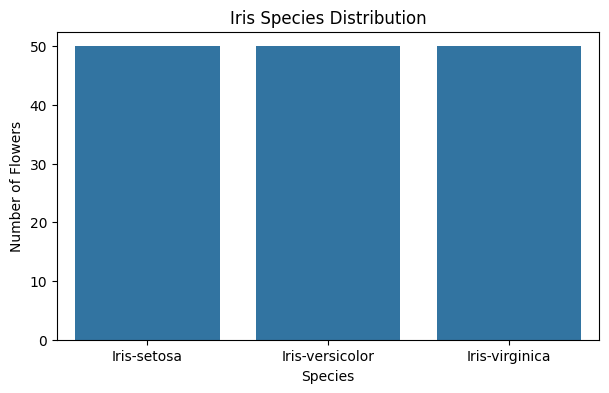

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 4))

sns.countplot(data=df, x='Species')

plt.title("Iris Species Distribution")
plt.xlabel("Species")
plt.ylabel("Number of Flowers")

plt.savefig("species_distribution.png")
plt.show()

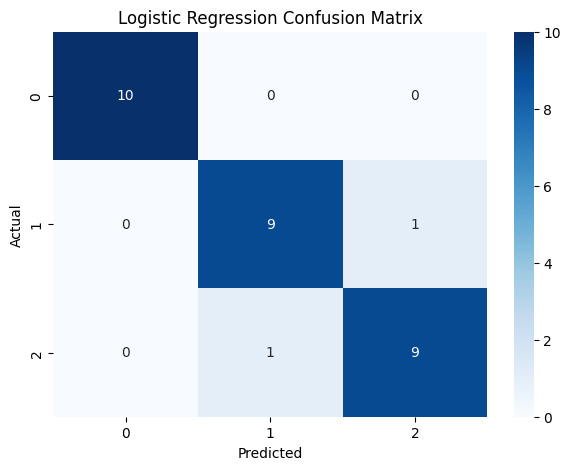

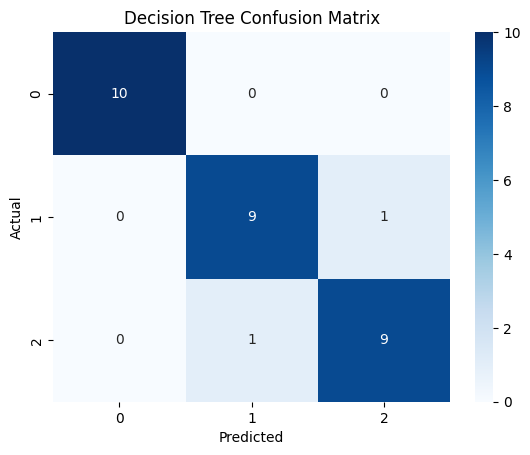

In [ ]:
from sklearn.metrics import confusion_matrix

plt.figure(figsize=(7, 5))

for name, model in models.items():

    y_pred = model.predict(X_test)
    cm = confusion_matrix(y_test, y_pred)

    sns.heatmap(
        cm, annot=True, fmt='d',
        cmap='Blues'
    )

    plt.title(name + " Confusion Matrix")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")

    plt.savefig(name.replace(" ", "_") + "_confusion_matrix.png")
    plt.show()
    plt.close()

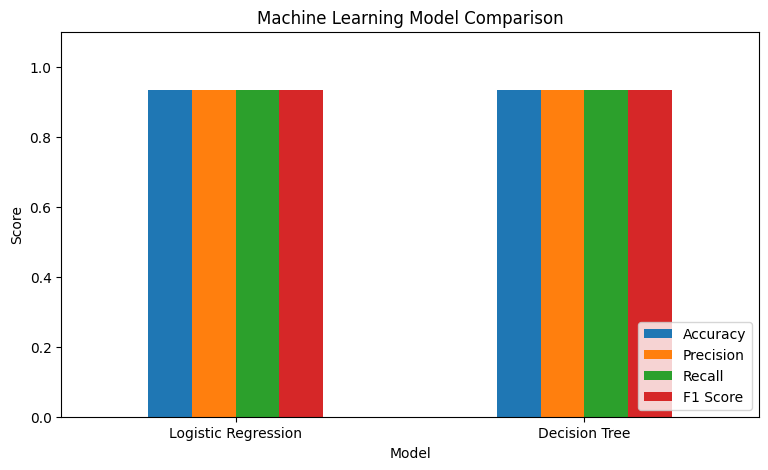

In [ ]:
results_df.set_index('Model').plot(
    kind='bar', figsize=(9, 5)
)

plt.title("Machine Learning Model Comparison")
plt.ylabel("Score")
plt.ylim(0, 1.1)
plt.xticks(rotation=0)
plt.legend(loc='lower right')

plt.savefig("model_comparison.png")
plt.show()

In [ ]:
results_df.to_csv("model_results.csv", index=False)

print("Results saved successfully!")

Results saved successfully!


In [ ]:
import zipfile
import os

files_to_save = [
    "species_distribution.png",
    "Logistic_Regression_confusion_matrix.png",
    "Decision_Tree_confusion_matrix.png",
    "model_comparison.png",
    "model_results.csv"
]

with zipfile.ZipFile("Iris_Results.zip", "w") as z:
    for file in files_to_save:
        if os.path.exists(file):
            z.write(file)

from google.colab import files
files.download("Iris_Results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
display(results_df.round(3))

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.933,0.933,0.933,0.933
1,Decision Tree,0.933,0.933,0.933,0.933
